# STiMUS-HAI: effect of the artefact-selection rule

This notebook analyses the two BehaviorSpace experiments run with the modified
STiMUS-HAI v3.1 model, in which the deterministic artefact-selection rule
(`argmax`) can be replaced by two probabilistic rules from the Ant Colony
Optimization literature:

| Rule | How a contributor chooses among visible artefacts |
|---|---|
| `argmax` (original) | Always the artefact with the highest stigmergic weight $W_i$ equivalent to STiMUS-HAI v3.1 |
| `proportional` | Random, with probability $P(i) = W_i / \sum_j W_j$ (Ant System) |
| `acs` | `argmax` with probability $q_0 = 0.9$, otherwise `proportional` (Ant Colony System) |

**Hypotheses**
The present notebook aims to work over two main hypotesis:

- **H1.** Replacing the deterministic rule with a probabilistic rule reduces the
  concentration of edits on a few artefacts.
- **H2.** Under the probabilistic rule, the task-completion rate and the share of
  artefacts reaching completeness $\geq 0.9$ are higher than under the original rule.

**Experiments**

The experiments were based on the Experiment 11 (E11) of the original work, which was saved in the public model of STiMUS-HAI v3.1 implemented in NetLogo. For that base, we introduced somo adittional parameters in order to capture emergency associated to probabilistic selection of artefacts.

**Experiment A:**
 For experiment A, all the parameters of (E11) was taken. In addition, new parameters: `judgment-share` , `selection-rule`, and `q0` were added. This parameter were maintaned in Experiment B

**Experiment B:**
 For experiment B, It's basically the same Experiment A but in a long horizon, equivalet to 3000 ticks. This definition was defined dut to a convergence in few artefacts was observed in long horizonts for original project, so we studied how probabilistic selection could help to lead with this

| | Experiment A (main) | Experiment B (long horizon) |
|---|---|---|
| File | `main_experiment_500_50.csv` | `main_experimentLong_3000_50.csv` |
| Design | E11_parameters × 3 rules: `ai-share` {0, 0.1, 0.25, 0.5} × `vision-radius` {2, 5} × `p-explicit` {0, 0.5, 1} × `mutualism-gain-factor` {0, 0.06, 0.15} | `ai-share` {0, 0.1, 0.25, 0.5} × 3 rules; `vision-radius` = 5, `p-explicit` = 0.5, `mutualism-gain-factor` = 0.06 |
| Replications | 50 per condition (216 conditions, 10,800 runs) | 50 per condition (12 conditions, 600 runs) |
| Run length | 500 ticks, outputs at the end | 3000 ticks, outputs every 50 ticks |

Fixed in both: 25 `contributors`, 25 `tasks`, 5 `topics`, `pheromone enabled`,
`evaporation` 0.05, `diffusion` 0.05, `edit increment` 0.6, `lambda-smm` 0.01,
`activity probability` 0.7, `judgment-share` 0, $q_0 = 0.9$.

**Structure of the notebook**

1. Setup and helper functions
2. Loading the data and sanity checks
3. Experiment A: H1 (concentration)
4. Experiment A: H2 (completion) and the mechanism behind it
5. Experiment A: effect sizes ($\eta^2$)
6. Experiment A: secondary outputs and robustness of the original findings
7. Experiment A: are 50 replications enough?
8. Experiment B: dynamics over 3000 ticks
9. Summary of findings



## 1. Setup and helper functions

**Statistical background used throughout of this notebook.** Each condition (mixed of configurations) is replicated 50 times with different random seeds. For an output $X$ we report the sample mean $\bar{X}$ and a 95 % confidence interval for the true mean $\mu$:

$$\bar{X} \pm t_{n-1,\,0.975}\,\frac{S}{\sqrt{n}}$$

where $S$ is the sample standard deviation, $n$ the number of runs and $t_{n-1,\,0.975}$ the critical value of Student's $t$ distribution with $n-1$ degrees of freedom. Two rules are considered clearly different when their
intervals do not overlap (a conservative criterion).

When several conditions are pooled (for example, all values of `vision-radius`, `p-explicit` and `mutualism-gain-factor` for a given rule), the result is a 
**marginal mean**: its interval reflects both random variation between replications and systematic variation between the pooled conditions.

In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
os.makedirs("figures", exist_ok=True)

# Fixed order and colour per rule (colour follows the rule in every figure).
RULES = ["argmax", "acs", "proportional"]
COLORS = {"argmax": "#2a78d6", "acs": "#eb6834", "proportional": "#1baf7a"}
MARKERS = {"argmax": "o", "acs": "s", "proportional": "^"}
LINES = {"argmax": "-", "acs": "--", "proportional": ":"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "legend.frameon": False,
})


def ci(x, conf=0.95): # Function to calculate confidence interval
    # Mean and t-based confidence interval of a sample.
    x = np.asarray(x, dtype=float)
    n = len(x)
    m = x.mean() #sample mean
    s = x.std(ddof=1) #sample standard deviation
    h = stats.t.ppf(1 - (1 - conf) / 2, n - 1) * s / np.sqrt(n) #margin of error
    return pd.Series({"mean": m, "lo": m - h, "hi": m + h, "sd": s, "n": n})


def ci_table(df, by, y):
    # Mean and 95 % CI of output y for each group defined by the columns in `by`.
    return df.groupby(by)[y].apply(ci).unstack() #with 3 rules and 4 values of ai-share, there will be 12 groups in the resulting table (900 values in each group)
                                                    #unstack() for reorganizing the resulting table to have a more readable format

def savefig(fig, name):
    fig.savefig(f"figures/{name}.png", bbox_inches="tight")

## 2. Loading the data and sanity checks

BehaviorSpace "table" files start with 6 lines of metadata (NetLogo version,
model, experiment name, date and world size), so they are skipped. Column names
are converted to Python-friendly names (`-` and spaces become `_`, `?` and
brackets are removed).

In [28]:
def load(path):
    df = pd.read_csv(path, skiprows=6)
    df.columns = (df.columns.str.replace(r"[\[\]\?]", "", regex=True)
                            .str.replace(r"[- ]", "_", regex=True))
    df["selection_rule"] = pd.Categorical(df["selection_rule"], RULES, ordered=True)
    return df

a = load("Results/main_experiment_500_50.csv")          # main_experiment_a
b = load("Results/main_experimentLong_3000_50.csv")     # main_experiment_b
print("A:", a.shape, " B:", b.shape)
a.head(10)

A: (10800, 57)  B: (36600, 28)


,run_number,num_contributors,num_tasks,topic_count,pheromone_enabled,evaporation_rate,diffusion_rate,edit_increment,lambda_smm,activity_probability,ai_share,vision_radius,p_explicit,mutualism_gain_factor,judgment_share,selection_rule,q0,step,ESR,coediting_density,...,task_edit_share,resource_edit_correlation,explicit_edit_share,explicit_hit_rate,explicit_fallback_rate,active_task_count,ESR_all,ESR_HH,human_smm,ai_pheromone_share,human_edit_share,ai_edit_share,hh_coediting_density,human_edits_count,ai_edits_count,hh_cross_author_edits,ai_pheromone_deposits,top1_share,complete_share,active_pages_share
0,3,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.583428,0.126667,...,0.018122,0.0,0.0,0.0,0.0,23,0.583428,0.583428,0.869527,0.0,1.0,0.0,0.126667,8774,0,5119,0,0.013563,0.103765,0.138659
1,8,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.503440,0.176667,...,0.019606,0.0,0.0,0.0,0.0,23,0.503440,0.503440,0.704178,0.0,1.0,0.0,0.176667,8722,0,4391,0,0.014905,0.081726,0.122130
2,10,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.403517,0.073333,...,0.055264,0.0,0.0,0.0,0.0,17,0.403517,0.403517,0.736930,0.0,1.0,0.0,0.073333,8758,0,3534,0,0.013131,0.109275,0.141414
3,9,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.575272,0.110000,...,0.031139,0.0,0.0,0.0,0.0,20,0.575272,0.575272,0.880309,0.0,1.0,0.0,0.110000,8735,0,5025,0,0.012707,0.106520,0.146006
4,4,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.591787,0.120000,...,0.050495,0.0,0.0,0.0,0.0,20,0.591787,0.591787,0.901378,0.0,1.0,0.0,0.120000,8694,0,5145,0,0.012882,0.102847,0.138659
5,7,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.488528,0.130000,...,0.058042,0.0,0.0,0.0,0.0,18,0.488528,0.488528,0.784908,0.0,1.0,0.0,0.130000,8804,0,4301,0,0.015107,0.112948,0.149679
6,5,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.530684,0.163333,...,0.076993,0.0,0.0,0.0,0.0,17,0.530684,0.530684,0.837294,0.0,1.0,0.0,0.163333,8832,0,4687,0,0.017097,0.098255,0.134986
7,13,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.443130,0.146667,...,0.056984,0.0,0.0,0.0,0.0,19,0.443130,0.443130,0.703008,0.0,1.0,0.0,0.146667,8792,0,3896,0,0.016606,0.099174,0.130395
8,2,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.623798,0.160000,...,0.060009,0.0,0.0,0.0,0.0,17,0.623798,0.623798,0.917103,0.0,1.0,0.0,0.160000,8732,0,5447,0,0.010880,0.106520,0.142332
9,1,25,25,5,True,0.05,0.05,0.6,0.01,0.7,0.0,2,0.0,0.0,0,argmax,0.9,500,0.464441,0.070000,...,0.037274,0.0,0.0,0.0,0.0,21,0.464441,0.464441,0.759487,0.0,1.0,0.0,0.070000,8746,0,4062,0,0.014178,0.106520,0.134986


**Note:** The size of "B" id due to we `set ticks mod 50 = 0` for saving measures along ticks and having better tracking of lock-in  phenomena which observed in the original study. In this case, 3000ticks/50 = 61(counting 0) and 600runsX61=36600

**Sanity checks.** Before analysing anything we confirm that the files contain what the design says: the expected number of runs, the three rules, the factor levels, `judgment-share` = 0, $q_0 = 0.9$, everywhere, and the right recording steps.

In [33]:
#A experiment verification
print("A_experiment  runs:", a["run_number"].nunique(), "(expected 10,800)")
print("A_experiment  steps recorded:", a["step"].unique()) #Step column should have the same  value in experiment A, 500
print("A_experiment  runs per rule:", a["selection_rule"].value_counts().to_dict())#3600 for each rule, for mixing of parameters 
for f in ["ai_share", "vision_radius", "p_explicit", "mutualism_gain_factor", "judgment_share", "q0"]: #setting verification along runs
    print(f"A_experiment {f}:", sorted(a[f].unique()))



A_experiment  runs: 10800 (expected 10,800)
A_experiment  steps recorded: [500]
A_experiment  runs per rule: {'argmax': 3600, 'acs': 3600, 'proportional': 3600}
A_experiment ai_share: [np.float64(0.0), np.float64(0.1), np.float64(0.25), np.float64(0.5)]
A_experiment vision_radius: [np.int64(2), np.int64(5)]
A_experiment p_explicit: [np.float64(0.0), np.float64(0.5), np.float64(1.0)]
A_experiment mutualism_gain_factor: [np.float64(0.0), np.float64(0.06), np.float64(0.15)]
A_experiment judgment_share: [np.int64(0)]
A_experiment q0: [np.float64(0.9)]


In [34]:
#B experiment verification
print("B_experiment  runs:", b["run_number"].nunique(), "(expected 600)")
print("B_experiment  steps: from", b["step"].min(), "to", b["step"].max(), "every", np.diff(sorted(b["step"].unique()))[0], "ticks;", b["step"].nunique(), "records per run")
print("B_experiment  runs per rule:", b.groupby("selection_rule", observed=True)["run_number"].nunique().to_dict())
for f in ["ai_share", "vision_radius", "p_explicit", "mutualism_gain_factor", "judgment_share", "q0"]: #setting verification along runs
    print(f"B_experiment {f}:", sorted(b[f].unique()))

B_experiment  runs: 600 (expected 600)
B_experiment  steps: from 0 to 3000 every 50 ticks; 61 records per run
B_experiment  runs per rule: {'argmax': 200, 'acs': 200, 'proportional': 200}
B_experiment ai_share: [np.float64(0.0), np.float64(0.1), np.float64(0.25), np.float64(0.5)]
B_experiment vision_radius: [np.int64(5)]
B_experiment p_explicit: [np.float64(0.5)]
B_experiment mutualism_gain_factor: [np.float64(0.06)]
B_experiment judgment_share: [np.int64(0)]
B_experiment q0: [np.float64(0.9)]


**Important: the amount of work is the same under all rules.** The selection rule should change *where* contributors work, not *how much* they work. If the total number of edits differed between rules, differences in completion could simply reflect more or less work. The table below shows that the total is practically identical (25 contributors × 0.7 activity × 500 ticks ≈ 8,750 edits).


**Note:** How is evidenced in the **B results** some parameters where simplified in order to optimize the time in long horizont test

In [35]:
ci_table(a, "selection_rule", "total_edits").round(1)

,mean,lo,hi,sd,n
selection_rule,,,,,
argmax,8749.1,8747.4,8750.8,51.0,3600.0
acs,8749.8,8748.2,8751.5,50.5,3600.0
proportional,8751.7,8750.0,8753.3,50.6,3600.0


## 3. Experiment A: H1, concentration of edits

H1 is measured with **`top1-share`**, a reporter added in this study: the share of all edits received by the most edited artefact. It approaches 1 when every contributor  converges on the same artefact (lock-in) and approaches 0 when work is spread.

### 3.1 Marginal means by rule and AI share

In [49]:
t_top1 = ci_table(a, ["selection_rule", "ai_share"], "top1_share")
t_top1.round(4)

mean      lo      hi      sd      n
selection_rule ai_share                                       
argmax         0.00      0.0131  0.0130  0.0132  0.0019  900.0
               0.10      0.0131  0.0130  0.0133  0.0020  900.0
               0.25      0.0131  0.0130  0.0132  0.0021  900.0
               0.50      0.0130  0.0128  0.0131  0.0020  900.0
acs            0.00      0.0121  0.0120  0.0122  0.0018  900.0
               0.10      0.0120  0.0119  0.0122  0.0017  900.0
               0.25      0.0120  0.0118  0.0121  0.0017  900.0
               0.50      0.0118  0.0117  0.0119  0.0017  900.0
proportional   0.00      0.0097  0.0095  0.0099  0.0028  900.0
               0.10      0.0096  0.0094  0.0097  0.0026  900.0
               0.25      0.0096  0.0094  0.0097  0.0027  900.0
               0.50      0.0094  0.0092  0.0096  0.0026  900.0

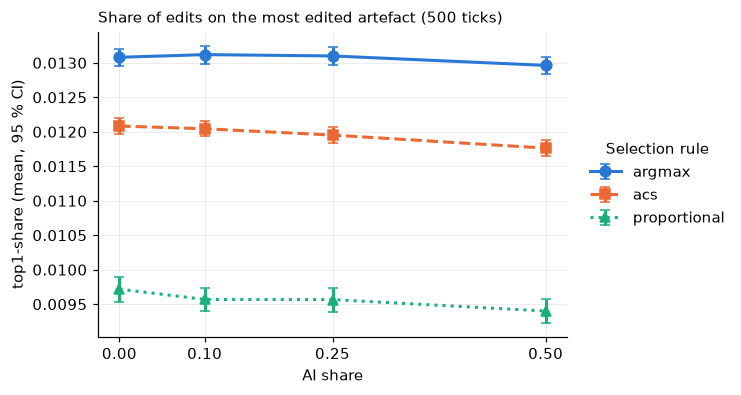

In [37]:
def plot_by_ai(df, y, ylabel, title, ax):
    tab = ci_table(df, ["selection_rule", "ai_share"], y).reset_index()
    for r in RULES:
        d = tab[tab["selection_rule"] == r]
        ax.errorbar(d["ai_share"], d["mean"], yerr=[d["mean"] - d["lo"], d["hi"] - d["mean"]],
                    color=COLORS[r], marker=MARKERS[r], ls=LINES[r], lw=2, ms=7,
                    capsize=3, label=r)
    ax.set_xlabel("AI share")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks(sorted(df["ai_share"].unique()))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
plot_by_ai(a, "top1_share", "top1-share (mean, 95 % CI)",
           "Share of edits on the most edited artefact (500 ticks)", ax)
ax.legend(title="Selection rule", loc="center left", bbox_to_anchor=(1.02, 0.5))
savefig(fig, "fig1_top1_by_rule_ai")
plt.show()

The intervals of the three rules do not overlap at any AI share: `proportional` gives the lowest concentration, `acs` an intermediate one and `argmax` the highest. 

An aspect that is relevant to mention here, an taking into account we are in the A experiment, it is that the **scale**: under `argmax` the most edited artefact receives only about 1.3 % of all edits. At 500 ticks the system has **not yet locked in**, so the reduction is real but happens on a concentration that is still low.
Experiment B (long Horizont) (Section 8) shows what happens in longer runs.

### 3.2 Where does the rule matter most? Breakdown by `p-explicit` and `vision-radius`

`p-explicit` is the probability that a contributor follows explicit task assignment instead of stigmergy. The selection rule only acts in the stigmergic branch, so its effect should be largest when `p-explicit` = 0.

On other hand `vision-radius` defines how large is the vision horizont for each agent so, it could expand the posibilities of selection and obviously affect the  `top1-share`.

In [38]:
ci_table(a, ["p_explicit", "selection_rule"], "top1_share")[["mean", "lo", "hi"]].unstack(0).round(4)

mean                      lo                      hi                
p_explicit         0.0     0.5     1.0     0.0     0.5     1.0     0.0     0.5     1.0
selection_rule                                                                        
argmax          0.0131  0.0130  0.0131  0.0130  0.0129  0.0130  0.0132  0.0131  0.0132
acs             0.0115  0.0121  0.0123  0.0114  0.0120  0.0122  0.0116  0.0122  0.0124
proportional    0.0067  0.0107  0.0113  0.0066  0.0106  0.0112  0.0067  0.0108  0.0115

In [39]:
ci_table(a, ["vision_radius", "selection_rule"], "top1_share")[["mean", "lo", "hi"]].unstack(0).round(4)

mean              lo              hi        
vision_radius        2       5       2       5       2       5
selection_rule                                                
argmax          0.0139  0.0123  0.0138  0.0122  0.0140  0.0123
acs             0.0125  0.0114  0.0124  0.0114  0.0126  0.0115
proportional    0.0101  0.0090  0.0100  0.0089  0.0102  0.0091

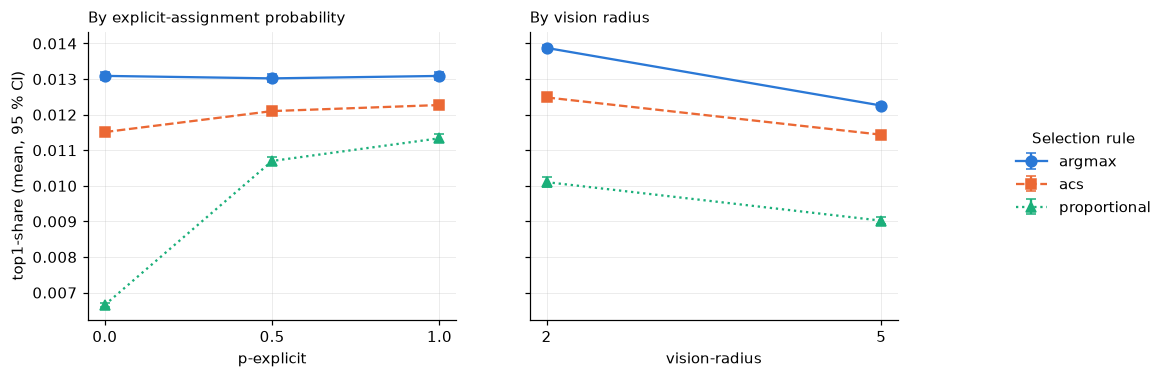

In [45]:
def plot_by_factor(df, y, factor, ylabel, title, ax):
    tab = ci_table(df, ["selection_rule", factor], y).reset_index()
    levels = sorted(df[factor].unique())
    x = np.arange(len(levels))
    width = 0
    for k, r in enumerate(RULES):
        d = tab[tab["selection_rule"] == r].set_index(factor).loc[levels]
        ax.errorbar(x + (k - 1) * width, d["mean"],
                    yerr=[d["mean"] - d["lo"], d["hi"] - d["mean"]],
                    color=COLORS[r], marker=MARKERS[r], ls=LINES[r], lw=1.5,
                    ms=7, capsize=3, label=r)
    ax.set_xticks(x, [str(v) for v in levels])
    ax.set_xlabel(factor.replace("_", "-"))
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
plot_by_factor(a, "top1_share", "p_explicit", "top1-share (mean, 95 % CI)",
               "By explicit-assignment probability", axes[0])
plot_by_factor(a, "top1_share", "vision_radius", "", "By vision radius", axes[1])

# Legend outside, to the right of both panels
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Selection rule",
           loc="center left", bbox_to_anchor=(1.0, 0.5))

savefig(fig, "fig2_top1_by_pexplicit_vision")
plt.show()


As expected, the gap between rules is largest with pure stigmergy (`p-explicit` = 0) and shrinks as explicit assignment takes over. With a larger vision radius, concentration is slightly lower for every rule, because contributors perceive more candidate artefacts. 

### 3.3 Coverage: how many artefacts receive work?

`top1-share` only looks at the single most edited artefact. Two complementary measures describe the whole distribution:

- **`active-pages-share`**: fraction of the 1089 artefacts edited at least once   (coverage).
- **`page-diversity`**: normalised Shannon entropy of edits *among the edited artefacts*. It measures how evenly edits are spread over the artefacts that were touched, **not** how many were touched: two artefacts edited equally give  the maximum value of 1. It must therefore be read together with  `active-pages-share`.

In [9]:
pd.concat({y: ci_table(a, "selection_rule", y)[["mean", "lo", "hi"]]
           for y in ["active_pages_share", "page_diversity"]}, axis=1).round(4)

active_pages_share                 page_diversity                
                             mean      lo      hi           mean      lo      hi
selection_rule                                                                  
argmax                     0.1407  0.1403  0.1410         0.9814  0.9812  0.9815
acs                        0.2622  0.2617  0.2626         0.9065  0.9062  0.9068
proportional               0.4790  0.4779  0.4802         0.9380  0.9377  0.9383

In this case, `proportional` touches roughly three times as many artefacts as `argmax`, and `acs` about twice as many. `page-diversity` is *higher* under `argmax` only because it is computed over a much smaller set of edited artefacts, which receive similar numbers of edits; this is exactly the caveat described above, and the reason why `top1-share` and `active-pages-share` are the primary measures of concentration in original version.

## 4. Experiment A: H2, completion

H2 is measured with two outputs:

- **`complete-share`** (added in this study): fraction of the 1089 artefacts with
  completeness $\geq 0.9$.
- **`task-completion-rate`** (original): fraction of the 25 designated tasks that
  reached completeness $\geq 0.9$.

### 4.1 Share of complete artefacts

In [50]:
ci_table(a, ["selection_rule", "ai_share"], "complete_share")[["mean", "lo", "hi"]].round(4)

mean      lo      hi
selection_rule ai_share                        
argmax         0.00      0.1045  0.1040  0.1051
               0.10      0.1041  0.1036  0.1046
               0.25      0.1042  0.1036  0.1047
               0.50      0.1047  0.1042  0.1052
acs            0.00      0.0656  0.0647  0.0664
               0.10      0.0653  0.0645  0.0662
               0.25      0.0653  0.0644  0.0662
               0.50      0.0663  0.0654  0.0672
proportional   0.00      0.0135  0.0129  0.0141
               0.10      0.0135  0.0129  0.0142
               0.25      0.0136  0.0129  0.0142
               0.50      0.0136  0.0130  0.0142

In [53]:
ci_table(a, ["selection_rule", "p_explicit"], "complete_share")[["mean", "lo", "hi"]].round(4)

mean      lo      hi
selection_rule p_explicit                        
argmax         0.0         0.1031  0.1027  0.1035
               0.5         0.1041  0.1037  0.1046
               1.0         0.1058  0.1054  0.1063
acs            0.0         0.0605  0.0598  0.0613
               0.5         0.0677  0.0669  0.0684
               1.0         0.0686  0.0679  0.0693
proportional   0.0         0.0001  0.0001  0.0002
               0.5         0.0196  0.0194  0.0198
               1.0         0.0209  0.0207  0.0210

In [54]:
ci_table(a, ["selection_rule", "p_explicit"], "task_completion_rate")[["mean", "lo", "hi"]].round(4)

mean      lo      hi
selection_rule p_explicit                        
argmax         0.0         0.2175  0.2130  0.2220
               0.5         0.7213  0.7089  0.7337
               1.0         0.7632  0.7508  0.7757
acs            0.0         0.1464  0.1421  0.1508
               0.5         0.7646  0.7533  0.7759
               1.0         0.8236  0.8134  0.8338
proportional   0.0         0.0009  0.0006  0.0013
               0.5         0.8527  0.8446  0.8608
               1.0         0.9076  0.9013  0.9139

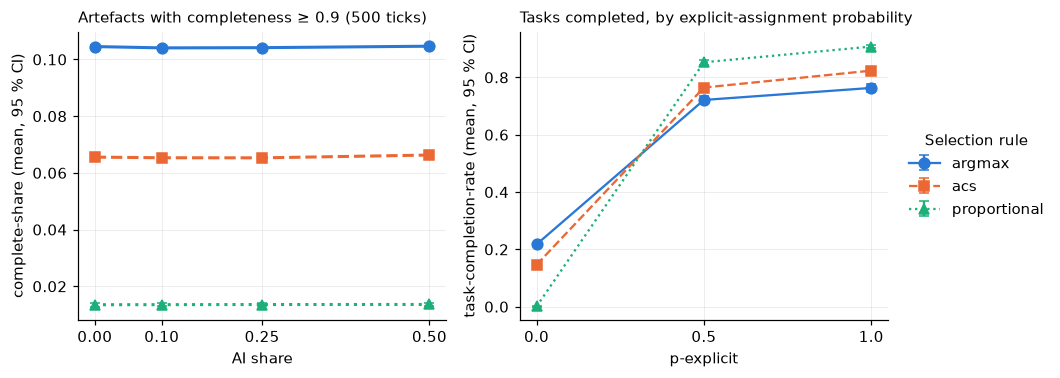

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
plot_by_ai(a, "complete_share", "complete-share (mean, 95 % CI)",
           "Artefacts with completeness ≥ 0.9 (500 ticks)", axes[0])
plot_by_factor(a, "task_completion_rate", "p_explicit",
               "task-completion-rate (mean, 95 % CI)",
               "Tasks completed, by explicit-assignment probability", axes[1])
axes[1].legend(title="Selection rule", loc="center left", bbox_to_anchor=(1.02, 0.5))

savefig(fig, "fig3_completion_500")
plt.show()

The result is the **opposite** of H2: after 500 ticks,
`argmax` completes the most artefacts (about 10 % of them, ≈ 114 artefacts),
`acs` fewer and `proportional` very few. The reason follows from the editing
rules. Raising an artefact from its initial completeness ($U(0, 0.2)$) to 0.9
takes on the order of 70 edits. `argmax` concentrates edits: it keeps working on
an artefact until its incompleteness term $(1 - c_i + 0.01)^{\beta}$ makes another
one more attractive, which acts like a *finish one before starting the next*
strategy. `proportional` spreads the same number of edits over many more
artefacts, so few of them accumulate enough edits to cross the threshold. This
is the exploration–exploitation trade-off (March, 1991): over a short horizon,
exploitation wins on completion.

### 4.2 Task completion depends on explicit assignment

In [12]:
ci_table(a, ["p_explicit", "selection_rule"], "task_completion_rate")[["mean", "lo", "hi"]].unstack(0).round(3)

mean                   lo                   hi              
p_explicit        0.0    0.5    1.0    0.0    0.5    1.0    0.0    0.5    1.0
selection_rule                                                               
argmax          0.218  0.721  0.763  0.213  0.709  0.751  0.222  0.734  0.776
acs             0.146  0.765  0.824  0.142  0.753  0.813  0.151  0.776  0.834
proportional    0.001  0.853  0.908  0.001  0.845  0.901  0.001  0.861  0.914

**Reading (right panel of the figure above).** The effect of the rule on tasks
**reverses** with `p-explicit`:

- With pure stigmergy (`p-explicit` = 0), tasks are completed only by chance,
  and `proportional` completes almost none: spreading work prevents any task from
  accumulating enough edits.
- With explicit assignment (`p-explicit` = 0.5 or 1), `proportional` completes
  the **most** tasks.

Pooling over `p-explicit` hides this interaction, which is why the marginal means
of the three rules overlap. The next cell explores the mechanism.

### 4.3 Mechanism: exploration helps contributors find tasks

Explicit assignment only works if a task is **visible** to the contributor. The
reporter `explicit-hit-rate` is the fraction of explicit attempts in which a
visible task was found. Under `proportional`, contributors move across many
more artefacts, and therefore across more of the world, so they see tasks more
often.

In [13]:
ci_table(a[a["p_explicit"] > 0], ["p_explicit", "selection_rule"],
         "explicit_hit_rate")[["mean", "lo", "hi"]].unstack(0).round(3)

mean            lo            hi       
p_explicit        0.5    1.0    0.5    1.0    0.5    1.0
selection_rule                                          
argmax          0.151  0.136  0.148  0.133  0.153  0.138
acs             0.170  0.147  0.167  0.145  0.172  0.149
proportional    0.231  0.159  0.229  0.158  0.233  0.160

**Reading.** With `p-explicit` = 0.5 the probability of finding a visible task is
clearly higher under `proportional` than under `argmax`. Exploration created by
the probabilistic rule increases task discovery, and explicit assignment then
does the work of completing them. The two mechanisms are complementary.

## 5. Experiment 3a: effect sizes ($\eta^2$)

To quantify how much of the variation of each output is explained by each
factor, we fit a factorial ANOVA with the main effects of all five factors and
the interactions between the selection rule and each of the other factors:

`y ~ rule * (ai_share + vision_radius + p_explicit + mutualism_gain_factor)`

and compute $\eta^2 = SS_{\text{effect}} / SS_{\text{total}}$, the proportion of
the total variance explained by each term (the same effect size used by the
original authors). As a rough guide, $\eta^2 \approx 0.01$ is small, $0.06$
medium and $\geq 0.14$ large. With 10,800 runs almost every term is
statistically significant, so the effect size, not the p-value, is what matters.

In [14]:
def eta2_table(df, outputs):
    out = {}
    for y in outputs:
        model = smf.ols(f"{y} ~ C(selection_rule) * (C(ai_share) + C(vision_radius)"
                        " + C(p_explicit) + C(mutualism_gain_factor))", data=df).fit()
        aov = sm.stats.anova_lm(model, typ=2)
        out[y] = aov["sum_sq"] / aov["sum_sq"].sum()
    tab = pd.DataFrame(out)
    tab.index = (tab.index.str.replace("C(", "", regex=False)
                          .str.replace(")", "", regex=False))
    return tab

eta = eta2_table(a, ["top1_share", "active_pages_share", "complete_share",
                     "task_completion_rate", "mean_quality"])
eta.round(3)

,top1_share,active_pages_share,complete_share,task_completion_rate,mean_quality
selection_rule,0.312,0.975,0.926,0.000,0.942
ai_share,0.001,0.000,0.000,0.000,0.000
vision_radius,0.057,0.002,0.009,0.092,0.007
p_explicit,0.092,0.001,0.015,0.785,0.001
mutualism_gain_factor,0.004,0.000,0.000,0.000,0.001
selection_rule:ai_share,0.000,0.000,0.000,0.000,0.000
selection_rule:vision_radius,0.003,0.002,0.015,0.006,0.000
selection_rule:p_explicit,0.122,0.001,0.009,0.036,0.002
selection_rule:mutualism_gain_factor,0.000,0.000,0.000,0.000,0.001
Residual,0.408,0.019,0.026,0.080,0.045


**Reading.** The selection rule is the dominant factor for concentration,
coverage, complete artefacts and mean quality. For `task-completion-rate`,
`p-explicit` dominates and the rule acts mainly through its interaction with
`p-explicit` (Section 4.2). The AI share explains practically nothing of these
outputs. The `Residual` row is the variance left to randomness between
replications.

## 6. Experiment 3a: secondary outputs and robustness of the original findings

### 6.1 Quality and co-editing

Two further outputs describe the system as a whole:

- **`mean-quality`**: mean quality over all 1089 artefacts.
- **`coediting-density`**: density of the co-editing network. In the calibration
  of the human-only model against Scratch wiki communities, simulated density
  stayed around 0.12 while empirical densities ranged from 0.13 to 0.80.

In [15]:
pd.concat({y: ci_table(a, "selection_rule", y)[["mean", "lo", "hi"]]
           for y in ["mean_quality", "coediting_density"]}, axis=1).round(3)

mean_quality               coediting_density              
                       mean     lo     hi              mean     lo     hi
selection_rule                                                           
argmax                0.194  0.194  0.195             0.233  0.228  0.238
acs                   0.213  0.213  0.213             0.274  0.268  0.280
proportional          0.301  0.300  0.301             0.521  0.513  0.530

**Reading.** Spreading the work raises the *mean* quality of the repository even
though fewer artefacts are completed: many artefacts improve a little instead of
a few improving a lot. The co-editing network also becomes much denser under
`proportional`, because contributors meet on many more artefacts. This
suggests that the original rule may be one reason why the model under-estimated
co-editing density in the calibration; testing this would require repeating
the calibration and is left for future work.

### 6.2 Robustness of the original finding: the ESR-all vs ESR-HH gap

The main result of the original STiMUS-HAI experiment E11 is that, as the AI
share grows, the human-only edit succession ratio (`ESR-HH`) falls while the
aggregate ratio (`ESR-all`) stays stable, so aggregate indicators hide a change
in human coordination. If this finding is robust, it should appear under all
three rules.

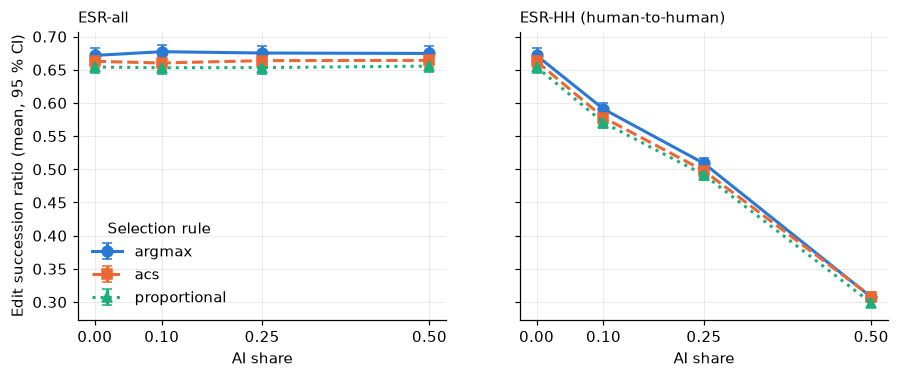

mean                         lo                         hi                    
selection_rule argmax    acs proportional argmax    acs proportional argmax    acs proportional
ai_share                                                                                       
0.00            0.000  0.000        0.000  0.000  0.000        0.000  0.000  0.000        0.000
0.10            0.086  0.082        0.083  0.084  0.080        0.081  0.089  0.085        0.085
0.25            0.166  0.166        0.162  0.162  0.162        0.158  0.171  0.170        0.165
0.50            0.367  0.356        0.357  0.359  0.348        0.351  0.375  0.363        0.363

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
plot_by_ai(a, "ESR_all", "Edit succession ratio (mean, 95 % CI)", "ESR-all", axes[0])
plot_by_ai(a, "ESR_HH", "", "ESR-HH (human-to-human)", axes[1])
axes[0].legend(title="Selection rule")
savefig(fig, "fig4_esr_gap_by_rule")
plt.show()

gap = a.assign(gap=a["ESR_all"] - a["ESR_HH"])
ci_table(gap, ["selection_rule", "ai_share"], "gap")[["mean", "lo", "hi"]].unstack(0).round(3)

**Reading.** The pattern of the original study is reproduced under all three
rules: `ESR-all` is flat while `ESR-HH` falls with the AI share by almost the
same amount. The original finding is therefore **robust to the selection rule**,
which supports its generality.

## 7. Experiment 3a: are 50 replications enough?

The number of replications $n$ needed to estimate a mean with a maximum relative
error $d$ (here 5 % of the mean) at 95 % confidence is

$$n \geq \left(\frac{t_{n-1,\,0.975}\,S}{d\,\bar{X}}\right)^2.$$

We compute it for every one of the 216 conditions, using the observed $S$ and
$\bar{X}$. Conditions whose mean is practically zero are excluded, because a
relative error is meaningless there (for example, `complete-share` under
`proportional` with `p-explicit` = 0); the threshold is a mean below 0.001.

In [17]:
def required_n(df, y, d=0.05, min_mean=0.001):
    keys = ["selection_rule", "ai_share", "vision_radius", "p_explicit",
            "mutualism_gain_factor"]
    g = df.groupby(keys, observed=True)[y].agg(["mean", "std", "count"])
    g = g[g["mean"] > min_mean]
    t = stats.t.ppf(0.975, g["count"] - 1)
    g["n_req"] = np.ceil((t * g["std"] / (d * g["mean"])) ** 2)
    return g["n_req"]

rows = {}
for y in ["top1_share", "active_pages_share", "complete_share",
          "task_completion_rate", "mean_quality"]:
    n = required_n(a, y)
    rows[y] = {"conditions": len(n), "median n": n.median(),
               "max n": n.max(), "share with n <= 50": (n <= 50).mean()}
pd.DataFrame(rows).T.round(2)

,conditions,median n,max n,share with n <= 50
top1_share,216.0,29.0,78.0,0.94
active_pages_share,216.0,6.0,12.0,1.00
complete_share,192.0,11.5,53.0,0.99
task_completion_rate,200.0,40.0,39560.0,0.60
mean_quality,216.0,3.0,6.0,1.00


**Reading.** For most outputs 50 replications give a 5 % relative precision in
almost every condition. Outputs that need more replications in some conditions
are those whose mean is small or highly variable (task completion with few
completed tasks); for them, the confidence intervals reported above are the
honest measure of precision.

## 8. Experiment 3b: dynamics over 3000 ticks

Experiment 3a measures the system at a single horizon (500 ticks). Because the
repository never reaches a steady state (completeness and quality only grow),
the analysis is **transient**: outputs are measured at fixed horizons rather than
after a warm-up period. Experiment 3b follows the system for 3000 ticks, recording
outputs every 50 ticks, in one intermediate condition (`vision-radius` = 5,
`p-explicit` = 0.5, `mutualism-gain-factor` = 0.06). The four AI-share levels
are pooled (200 runs per rule and tick) after checking that the AI share has
practically no effect (Section 8.4).

### 8.1 Consistency check with experiment 3a

The tick-500 records of 3b correspond to the same condition as a subset of 3a.
Both experiments used different seeds, so values should agree statistically, not
exactly.

In [18]:
sub_a = a[(a["vision_radius"] == 5) & (a["p_explicit"] == 0.5) &
          (a["mutualism_gain_factor"] == 0.06)]
b500 = b[b["step"] == 500]
pd.concat({"3a (500 ticks)": ci_table(sub_a, "selection_rule", "top1_share")[["mean", "lo", "hi"]],
           "3b at tick 500": ci_table(b500, "selection_rule", "top1_share")[["mean", "lo", "hi"]]},
          axis=1).round(4)

3a (500 ticks)                 3b at tick 500                
                         mean      lo      hi           mean      lo      hi
selection_rule                                                              
argmax                 0.0122  0.0119  0.0124         0.0121  0.0118  0.0124
acs                    0.0112  0.0110  0.0113         0.0112  0.0110  0.0115
proportional           0.0098  0.0096  0.0100         0.0096  0.0094  0.0098

The intervals overlap for every rule, so both experiments describe the same
system.

### 8.2 Trajectories

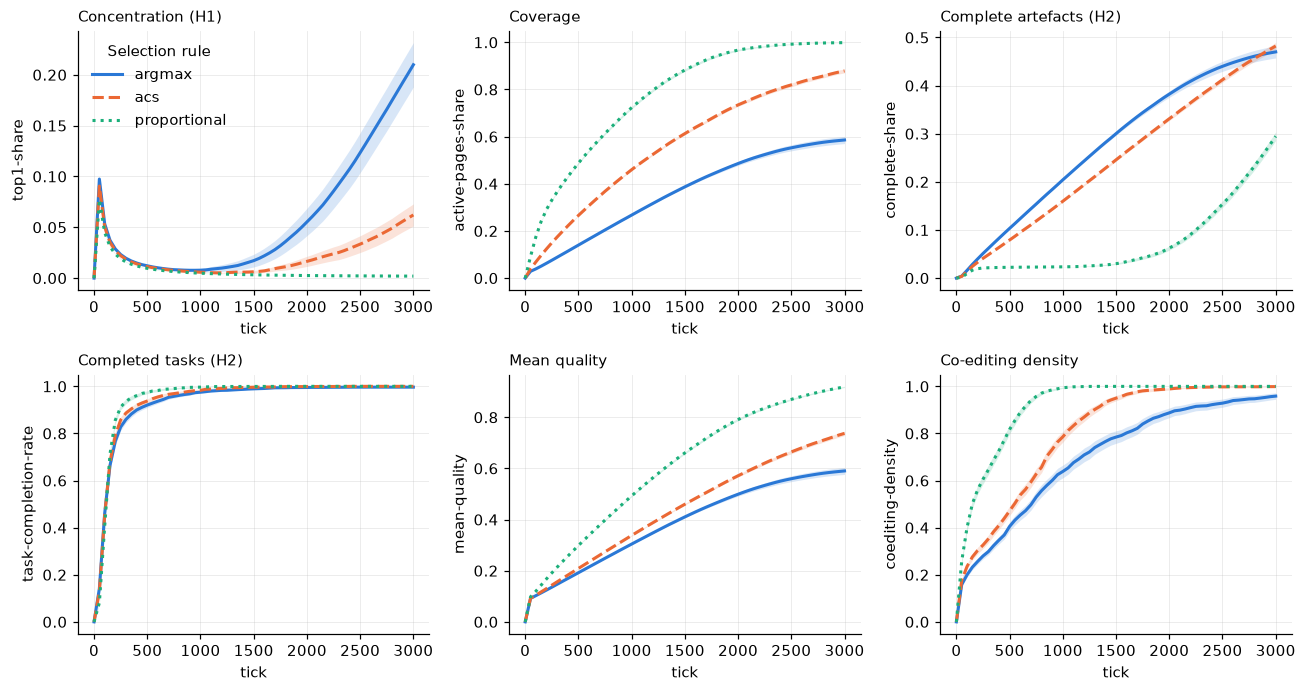

In [19]:
def trajectory(df, y):
    return (df.groupby(["selection_rule", "step"], observed=True)[y]
              .apply(ci).unstack().reset_index())

panels = [("top1_share", "top1-share", "Concentration (H1)"),
          ("active_pages_share", "active-pages-share", "Coverage"),
          ("complete_share", "complete-share", "Complete artefacts (H2)"),
          ("task_completion_rate", "task-completion-rate", "Completed tasks (H2)"),
          ("mean_quality", "mean-quality", "Mean quality"),
          ("coediting_density", "coediting-density", "Co-editing density")]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (y, lab, title) in zip(axes.flat, panels):
    tr = trajectory(b, y)
    for r in RULES:
        d = tr[tr["selection_rule"] == r]
        ax.plot(d["step"], d["mean"], color=COLORS[r], ls=LINES[r], lw=2, label=r)
        ax.fill_between(d["step"], d["lo"], d["hi"], color=COLORS[r], alpha=0.18, lw=0)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("tick")
    ax.set_ylabel(lab)
axes[0, 0].legend(title="Selection rule")
fig.tight_layout()
savefig(fig, "fig5_trajectories_3000")
plt.show()

**Reading.**

- **Concentration (H1).** Under `argmax`, `top1-share` stays low (and even
  decreases) during the first ~1500 ticks and then rises steeply
  (the short peak in the first ticks only reflects the very small number of
  edits at that point): this is the **lock-in**, in which most
  contributors converge on one artefact. `acs` shows a much weaker version, and
  `proportional` never locks in; its concentration keeps decreasing.
- **Coverage.** `proportional` reaches almost every artefact; `argmax` leaves a
  large part of the repository untouched.
- **Complete artefacts (H2).** `argmax` leads at first, but its growth slows
  down as lock-in sets in, because edits are wasted on artefacts that are already
  complete. `acs` reaches the same level by the end of the run (its mean
  overtakes `argmax` at about tick 2900, with overlapping intervals at 3000). `proportional` starts
  slowly but accelerates late, as many artefacts approach the threshold at the
  same time.
- **Tasks (H2).** All rules complete practically every task long before 3000
  ticks; differences only exist at short horizons.
- **Quality and co-editing.** `proportional` gives the highest mean quality and
  the densest co-editing network throughout.

### 8.3 Values at fixed horizons

In [20]:
horizons = [500, 1000, 2000, 3000]
outs = ["top1_share", "complete_share", "task_completion_rate", "mean_quality"]
tabs = {}
for y in outs:
    t = (b[b["step"].isin(horizons)]
         .groupby(["step", "selection_rule"], observed=True)[y].apply(ci).unstack())
    tabs[y] = t.apply(lambda r: f"{r['mean']:.3f} [{r['lo']:.3f}, {r['hi']:.3f}]", axis=1)
pd.DataFrame(tabs)

top1_share        complete_share  task_completion_rate          mean_quality
step selection_rule                                                                                        
500  argmax          0.012 [0.012, 0.012]  0.103 [0.102, 0.104]  0.921 [0.910, 0.931]  0.192 [0.191, 0.193]
     acs             0.011 [0.011, 0.011]  0.079 [0.078, 0.080]  0.938 [0.929, 0.947]  0.209 [0.208, 0.210]
     proportional    0.010 [0.009, 0.010]  0.022 [0.022, 0.023]  0.975 [0.969, 0.981]  0.299 [0.297, 0.300]
1000 argmax          0.008 [0.006, 0.010]  0.204 [0.202, 0.206]  0.975 [0.970, 0.980]  0.304 [0.302, 0.306]
     acs             0.006 [0.006, 0.006]  0.160 [0.158, 0.162]  0.983 [0.978, 0.988]  0.338 [0.336, 0.340]
     proportional    0.005 [0.005, 0.005]  0.023 [0.023, 0.024]  0.997 [0.995, 0.998]  0.493 [0.489, 0.496]
2000 argmax          0.055 [0.042, 0.069]  0.382 [0.376, 0.389]  0.995 [0.993, 0.997]  0.499 [0.492, 0.507]
     acs             0.016 [0.012, 0.021]  0.331 [0.327, 0.335]  0.999 [0.998, 1.000]  0.571 [0.566, 0.576]
     proportional    0.003 [0.002, 0.003]  0.062 [0.058, 0.067]  1.000 [1.000, 1.000]  0.791 [0.787, 0.796]
3000 argmax          0.210 [0.188, 0.232]  0.470 [0.457, 0.483]  0.997 [0.995, 0.998]  0.590 [0.577, 0.604]
     acs             0.062 [0.051, 0.073]  0.482 [0.475, 0.489]  1.000 [1.000, 1.000]  0.737 [0.729, 0.745]
     proportional    0.002 [0.002, 0.002]  0.295 [0.286, 0.304]  1.000 [1.000, 1.000]  0.919 [0.917, 0.921]

In [21]:
# First recorded tick at which the acs mean of complete-share exceeds argmax's
tr = trajectory(b, "complete_share").pivot(index="step", columns="selection_rule", values="mean")
cross = tr.index[(tr["acs"] > tr["argmax"])]
print("acs overtakes argmax in complete-share at tick:",
      cross.min() if len(cross) else "never within 3000 ticks")

# Onset of lock-in: first tick at which argmax top1-share exceeds twice its tick-500 value
tt = trajectory(b, "top1_share").pivot(index="step", columns="selection_rule", values="mean")
onset = tt.index[(tt.index > 500) & (tt["argmax"] > 2 * tt.loc[500, "argmax"])]
print("argmax top1-share doubles its tick-500 value at tick:", onset.min())

acs overtakes argmax in complete-share at tick: 2900
argmax top1-share doubles its tick-500 value at tick: 1650


### 8.4 Does the AI share change the long-run result?

In [22]:
ci_table(b[b["step"] == 3000], ["selection_rule", "ai_share"],
         "top1_share")[["mean", "lo", "hi"]].unstack(0).round(4)

mean                           lo                           hi                     
selection_rule  argmax     acs proportional  argmax     acs proportional  argmax     acs proportional
ai_share                                                                                             
0.00            0.1867  0.0606        0.002  0.1482  0.0437       0.0019  0.2251  0.0775        0.002
0.10            0.2565  0.0680        0.002  0.2082  0.0433       0.0019  0.3048  0.0927        0.002
0.25            0.1848  0.0514        0.002  0.1417  0.0330       0.0019  0.2280  0.0697        0.002
0.50            0.2115  0.0686        0.002  0.1658  0.0412       0.0019  0.2572  0.0960        0.002

**Reading.** Under `acs` and `proportional` the AI share makes no difference.
Under `argmax` the differences between AI-share levels are not significant
(the intervals overlap), but the intervals are much wider than for the other
rules: once lock-in occurs, its strength depends on which artefact the
contributors converge on, so runs become much more variable. This variability is
itself a sign of the path dependence created by the deterministic rule.

## 9. Summary of findings

**H1 (concentration): supported.** The probabilistic rules reduce the
concentration of edits at every horizon, and the difference grows over time. At
500 ticks the reduction is clear but concentration is still low for all rules.
In longer runs, the deterministic `argmax` rule produces lock-in, `acs` reduces
it strongly, and `proportional` eliminates it. The effect is largest when
contributors rely only on stigmergy (`p-explicit` = 0).

**H2 (completion): not supported as stated; the result depends on the horizon
and on explicit assignment.**

- *Complete artefacts.* At 500 ticks `argmax` completes more artefacts than the
  probabilistic rules, because concentrating work finishes artefacts faster
  (exploitation). Over longer runs lock-in slows `argmax` down, `acs` reaches
  the same level by 3000 ticks, and `proportional` accelerates late.
- *Tasks.* With pure stigmergy, `proportional` completes almost no tasks. With
  explicit assignment, it completes the most, because exploration increases the
  chance of seeing a task (higher explicit hit rate). In long runs all rules
  complete practically every task.

**Additional results.**

- Spreading work raises mean quality and co-editing density.
- The amount of work (total edits) is the same under all rules, so the
  differences come from where the work is done, not from how much.
- The main finding of the original study (`ESR-HH` falls with the AI share while
  `ESR-all` stays stable) is reproduced under all three rules, i.e., it is robust
  to the selection rule.
- The AI share has practically no effect on concentration or completion when
  `judgment-share` = 0.

**Interpretation.** The selection rule controls a trade-off between exploitation
(finishing a few artefacts quickly) and exploration (spreading effort, improving
the repository as a whole, discovering tasks and avoiding lock-in). `acs` offers
a balance between the two, controlled by $q_0$.